[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ryouy/GraduationThesis/blob/main/1112_cue_semantic_distance/cue_semantic_distance_selection.ipynb)

# 本実験のCue作成・意味的距離計測・刺激選定（パイロット）

**目的**：4概念（boat, bus, bicycle, motorcycle）について、事前に書いた候補Cue（各60文）を `sentence-transformers/all-mpnet-base-v2` で測定し、**近い・中程度・遠い関連Cue各4文＋無関係Cue4文**を選ぶ。X/Yの概念名をCueに含めず、結果を見ずに選定する。

- **重要**：距離数値は実際にColabで計測するまで未確定。0.3/0.6/0.9に合わせるのではなく、関連Cueの実測分布内の離れた領域から選ぶ。
- 「遠い」も**Xに弱く関連する文章**であり、無関係Cueとは分離する。
- **採用Cueは最初「暫定」**。内容の自然さ・関連性・Yとの混同を人手で確認した後、同じ距離を維持したまま最終版を凍結する。初回実行で「FINAL」と記録しない。
- 出力モデルQwenの応答・Probe・Logit Lensは**ここでは一切実行しない**。Cue選定と本実験の結果を分離する。

[本実験プロトコル](https://github.com/ryouy/GraduationThesis/blob/main/docs/main_experiment_protocol.md) / [独立Probe検証結果](https://github.com/ryouy/GraduationThesis/blob/main/1112_qwen_probe_independent_confirmation/results/20261112_newfacts_16targets_v1/analysis_summary.md)

## 1. ライブラリと再現性

**GPU不要（CPUで実行可能）**。Colab Secretsに `GITHUB_RESULTS_TOKEN`（リポジトリ Contents: Read & Write）を設定すると、結果をGitHubへ保存する。設定しない場合でもローカルにZIPを生成する。

In [1]:
%pip -q install 'sentence-transformers>=3.0,<6' 'pandas>=2,<3' 'matplotlib>=3.8,<4' 'huggingface-hub>=0.25,<2'

In [2]:
import re, os, json, sys, math, hashlib, platform, io, zipfile, traceback
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import sentence_transformers
from sentence_transformers import SentenceTransformer

SEED=20261112
RUN_ID='20261112_cue_distance_pilot_v1'
REPO='ryouy/GraduationThesis'
REMOTE_ROOT=f'1112_cue_semantic_distance/results/{RUN_ID}'
OUT=Path('/content')/RUN_ID if Path('/content').exists() else Path.cwd()/RUN_ID
OUT.mkdir(exist_ok=True,parents=True)
MODEL_ID='sentence-transformers/all-mpnet-base-v2'
GITHUB_SAVE=True
np.random.seed(SEED)
print('Output:',OUT,'CPU/GPU:',torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

Output: /content/20261112_cue_distance_pilot_v1 CPU/GPU: CPU


## 2. 候補Cueを用意（4概念×60文）

各概念につき、関連Cue **48文**（直接的関連12・場面的関連18・弱い間接的関連18）および無関係Cue **12文**。初期の `seed_type` は距離の正解ラベルではなく**作成意図**。近・中・遠の最終分類は実測の距離だけで決める。文章は新しく作成した刺激案であり、生成文の意味的妥当性は人手レビューが必要。

In [3]:
CANDIDATE_SEEDS = {'boat': {'direct': ['The vessel floated gently beside a wooden dock at sunrise.', 'A small watercraft carried two people across the calm lake.', 'The captain steered through the shallow channel toward the shore.', 'A narrow hull moved quietly over the open water.', 'Passengers stepped aboard the floating craft before the crossing.', 'The sailor tied a rope to a cleat near the pier.', 'The craft used oars to travel across the quiet pond.', 'A small outboard engine pushed the hull through the river.', 'The crew lowered an anchor before stopping in the bay.', 'A life jacket rested on the seat of a floating vessel.', 'The navigator checked the water depth near the harbor entrance.', 'The wooden craft rocked as waves reached the pier.'], 'context': ['Families waited at the lakeside dock for their afternoon excursion.', 'An island village depends on daily crossings to the mainland.', 'The harbor master announced that the tide was changing.', 'Workers prepared a short journey across the inlet.', 'Tourists watched a guide explain safety rules by the marina.', 'The lake was calm enough for a leisurely afternoon crossing.', 'A fishing crew returned with its catch after sunset.', 'Children watched travelers leave the shoreline toward the island.', 'The marina installed new hooks for securing ropes.', 'A guide described the route between two small islands.', 'The weather forecast warned of sudden waves near the coast.', 'The village schedules departures around high and low tides.', 'A weekend visitor rented equipment at the waterfront.', 'Several passengers carried bags down to the landing stage.', 'People gathered near the canal to begin a sightseeing tour.', 'The lakeside operator checked tickets before the morning departure.', 'A worker inspected the wooden jetty after a storm.', 'The crossing was delayed because thick fog covered the inlet.'], 'peripheral': ['The coastal town gets busy when summer visitors arrive.', 'Fishing traditions remain important to the local economy.', 'The river connects several villages along the valley.', 'The guide explained how strong winds affect travel plans.', 'Several visitors gathered to admire the scenery across the lake.', 'Local environmental regulations protect sensitive wildlife around the small island.', 'The family packed snacks before heading toward the waterfront.', 'A new bridge reduced travel time between two communities.', 'Waves left a line of seaweed along the beach.', 'The village museum displays maps of earlier trade routes.', 'The annual festival celebrates the region’s maritime history.', 'Residents discussed plans to improve access to the shore.', 'An old lighthouse still overlooks the rocky coast.', 'A travel writer visited small settlements beside the canal.', 'The weather station recorded unusually high winds overnight.', 'A local school organized an educational trip to the island.', 'The repair shop sells ropes and other outdoor supplies.', 'Visitors photographed the sunset from the edge of the harbor.']}, 'bus': {'direct': ['Passengers boarded a large road vehicle at the marked stop.', 'The driver opened the front doors before leaving the terminal.', 'A city route displayed its next destination above the windshield.', 'The vehicle carried dozens of commuters along a fixed route.', 'A passenger tapped a fare card upon entering the vehicle.', 'The driver pulled toward the curb to collect waiting riders.', 'Rows of seats lined the interior of the public road vehicle.', 'The route number appeared on the electronic destination sign.', 'The transit vehicle stopped at every scheduled neighborhood station.', 'A long passenger vehicle waited in the depot before dawn.', 'The fare machine printed a ticket for the afternoon journey.', 'A school route collected students near the playground entrance.'], 'context': ['Commuters checked the timetable posted beside the shelter.', 'The city extended public transport service into the evening.', 'The station announced delays along the northern route.', 'Passengers formed a line near the curb in heavy rain.', 'A transit operator updated the schedule for the weekend.', 'The downtown stop was crowded after the concert ended.', 'A visitor asked which route reaches the university entrance.', 'The transit authority introduced new contactless fare payments.', 'The morning journey passed several shops along the avenue.', 'A driver checked traffic conditions before beginning the route.', 'The ticket inspector walked through the crowded terminal.', 'Students waited under the shelter after their classes finished.', 'The city added a new covered waiting area near the library.', 'The transfer station connects residential streets with the center.', 'A passenger missed the last scheduled departure of the night.', 'Public transport workers discussed a revised evening timetable.', 'A commuter changed routes after a road closure downtown.', 'A group of visitors purchased day passes at the terminal.'], 'peripheral': ['City officials want to reduce traffic during the morning rush.', 'The neighborhood built a new shelter beside the main road.', 'Office workers commute from suburbs into the city center.', 'The city council debated how to fund public services.', 'The morning rain made the streets unusually slippery.', 'A university offers discounted travel passes to students.', 'An urban planner studied how residents move across districts.', 'The main street becomes crowded when schools close.', 'A large weekend festival attracted visitors from several surrounding neighborhoods.', 'The government released updated figures on urban mobility.', 'A pedestrian crossing was installed near the shopping area.', 'Local employers adjusted starting times to reduce congestion.', 'The city improved access to its central transport hub.', 'Residents complained about noise beside the busy avenue.', 'A new timetable was posted at the community center.', 'The transport ministry published an annual commuting survey.', 'A roadworks project changed several neighborhood travel patterns.', 'The council proposed a cleaner transport system for the region.']}, 'bicycle': {'direct': ['The rider turned the pedals while balancing on two narrow wheels.', 'A metal frame connected the handlebars to the rear wheel.', 'The cyclist adjusted the saddle before starting the morning ride.', 'A chain transferred the pedaling motion to the back wheel.', 'The rider squeezed the handlebar brakes near the crossing.', 'The two-wheeled machine leaned against the fence after the trip.', 'A bell rang as the rider approached people on the path.', 'The mechanic tightened a loose spoke on the front wheel.', 'A rider changed gears while climbing the steep hill.', 'The lightweight pedal-powered vehicle rolled along the cycle lane.', 'The helmeted rider placed both feet on the pedals.', 'The tire pump rested beside the wheel awaiting repair.'], 'context': ['Commuters locked their two-wheelers outside the railway station.', 'The city painted a protected lane beside the avenue.', 'A cycling club organized a weekend route through the hills.', 'The repair shop offered free tire checks before the race.', 'Students used a shared parking rack near the library.', 'A helmet is recommended on the riverside recreational trail.', 'The path was popular with riders on sunny afternoons.', 'A family planned a leisurely ride along the waterfront.', 'The community installed new stands near the park entrance.', 'A delivery worker followed the marked route through downtown.', 'The road signs warned riders about a steep descent.', 'The school hosted a workshop on safe urban cycling.', 'A traffic survey counted riders entering the city center.', 'The athlete practiced cornering on a quiet neighborhood road.', 'The city published a map of dedicated cycling paths.', 'Families gathered for a charity ride on Sunday morning.', 'The traveler packed a small pump and reflective jacket.', 'An outdoor shop advertised a spring maintenance clinic.'], 'peripheral': ['Health officials encourage residents to exercise outdoors regularly.', 'The riverside path connects several parks in the valley.', 'The city wants fewer cars near the school entrance.', 'An athlete trained every morning before going to work.', 'Outdoor equipment sales increased during the spring months.', 'The neighborhood planned safer streets for all travelers.', 'A volunteer group cleaned litter from the shared trail.', 'The hills become especially green after the first rains.', 'A community event promoted sustainable ways to commute.', 'The shop displayed reflective clothing for evening travel.', 'A city engineer reviewed designs for a new bridge.', 'Students explored different ways to reach their campus.', 'The regional council funded several active transportation programs.', 'The sports center opened early for local fitness groups.', 'The river crossing is closed during the annual festival.', 'The park added signs asking visitors to travel slowly.', 'A teenager enjoyed exploring quiet streets in the neighborhood.', 'The city published guidance on reducing traffic emissions.']}, 'motorcycle': {'direct': ['The rider started the engine and gripped the handlebars.', 'A helmeted traveler leaned the motorized two-wheeler into the turn.', 'The exhaust note grew louder as the throttle opened.', 'The mechanic inspected the chain and the front suspension.', 'The powered two-wheeled vehicle waited at the traffic light.', 'A rider shifted gears while accelerating down the open road.', 'The engine vibrated beneath the seat as the journey began.', 'The traveler parked the machine on its side stand.', 'The rider wore protective gloves and a reinforced jacket.', 'The fuel tank sat between the seat and handlebars.', 'The rear tire left a faint mark on the wet pavement.', 'The rider adjusted the mirrors before merging into traffic.'], 'context': ['A group of riders gathered at the mountain road viewpoint.', 'The licensing school taught safe handling of powered vehicles.', 'The touring club planned a weekend trip through winding roads.', 'A roadside mechanic offered maintenance for high-performance engines.', 'The helmet store displayed visors designed for highway travel.', 'The rider stopped at a service station to refill the tank.', 'Engine noise echoed across the valley during the rally.', 'The parking area reserved spaces for small motorized vehicles.', 'A traveler packed lightweight luggage for a long road trip.', 'The city reminded riders to use protective clothing.', 'The workshop inspected brake discs before the riding season.', 'A mountain pass attracted visitors seeking winding routes.', 'The driver checked the weather before leaving for the coast.', 'The road safety event included demonstrations of defensive riding.', 'People admired a classic machine at the weekend vehicle show.', 'The rally organizers marked sharp corners with warning signs.', 'A traveler cleaned dust from a helmet after a long tour.', 'The garage stocked replacement spark plugs and protective gear.'], 'peripheral': ['The highway curves sharply as it passes through the mountains.', 'An engine repair shop opened beside the industrial estate.', 'The region is known for scenic roads and weekend tourism.', 'Road safety campaigns encourage people to wear protective equipment.', 'The service station closes early during the winter months.', 'A motorsport event attracted visitors from distant cities.', 'The city introduced stricter limits on traffic noise.', 'A traveler took photographs beside the mountain pass.', 'The local mechanic specializes in small combustion engines.', 'The town proposed new parking spaces near the old market.', 'Outdoor clothing stores displayed jackets for cold weather.', 'The road became slippery after an unexpected rainstorm.', 'The government reviewed licensing rules for road users.', 'A popular touring route crosses several high mountain passes.', 'The festival featured restored machines from earlier decades.', 'A shop advertised replacement parts for recreational vehicles.', 'A fuel price increase affected transportation costs this month.', 'The landscape changes dramatically along the coastal highway.']}}
NEGATIVE_SEEDS = {'boat': ['The laboratory installed new microscopes for the biology course.', 'A baker measured flour before preparing the morning dough.', 'The astronomy lecture explained why distant stars appear red.', 'A musician practiced scales on a keyboard after dinner.', 'The software team revised its database access policy.', 'A greenhouse worker counted seedlings before planting them.', 'The library replaced several shelves in the history section.', 'The dentist scheduled a routine examination for next week.', 'The mathematics class studied prime numbers on Tuesday.', 'A museum curator cataloged ancient pottery from the valley.', 'The chef prepared mushroom soup for the evening menu.', 'A photographer adjusted the studio lighting before the portrait.'], 'bus': ['A florist arranged white flowers in a ceramic vase.', 'The astronomer measured the brightness of a distant galaxy.', 'A bakery displayed fresh bread beside the counter.', 'The scientist labeled samples from a soil experiment.', 'A pianist rehearsed a short melody before the concert.', 'The gardener watered tomatoes in a small greenhouse.', 'A translator revised a historical manuscript after lunch.', 'The chef prepared a dessert with fresh citrus fruit.', 'The museum exhibited paintings from the early nineteenth century.', 'A student solved a geometry problem on the whiteboard.', 'The medical team analyzed a tissue sample under a microscope.', 'The librarian cataloged new books for the poetry collection.'], 'bicycle': ['The chemist mixed two solutions in a glass container.', 'A pastry chef decorated a cake with fresh strawberries.', 'The orchestra rehearsed an unfamiliar symphony after lunch.', 'The astronomer observed a distant nebula through the telescope.', 'A botanist studied moss growing on a shaded rock.', 'The accountant carefully reviewed the quarterly financial statements.', 'The sculptor shaped wet clay into a decorative bowl.', 'A linguist compared grammar patterns across several languages.', 'The classroom displayed diagrams of the human digestive system.', 'The farmers harvested ripe apples from the hillside orchard.', 'The historian examined letters preserved in a wooden archive.', 'The researcher tested a new method for image compression.'], 'motorcycle': ['A scientist measured the acidity of the laboratory solution.', 'The chef baked a pie filled with seasonal berries.', 'A historian analyzed a handwritten document from the archive.', 'The pianist practiced a difficult passage at the conservatory.', 'The astronomer mapped a cluster of distant stars.', 'The botanist recorded the growth of tropical ferns.', 'The programmer tested a change to the search algorithm.', 'The librarian organized an exhibition of medieval poetry.', 'A ceramic artist painted a detailed pattern on a bowl.', 'The nutritionist described the vitamins found in leafy vegetables.', 'The student calculated the area of a geometric shape.', 'The photographer edited portraits from the indoor studio session.']}

## 3. Concept定義と比較相手Yを固定

本パイロットの比較相手Yは**新文章Probe検証でFDR感度分析を通過したペア**から、実験前に固定する：boat→bus、bus→helicopter、bicycle→submarine、motorcycle→helicopter。**距離選定の結果や今後の抑制実験の結果を見てYを変えない**。距離測定に用いる短い定義文は、Cueと同程度の英文で統一する。

In [4]:
TARGETS = {
  'boat': {'y':'bus', 'definition':'A boat is a relatively small watercraft that carries people or goods across rivers, lakes, or seas.'},
  'bus': {'y':'helicopter', 'definition':'A bus is a large road vehicle that carries many passengers along scheduled public transport routes.'},
  'bicycle': {'y':'submarine', 'definition':'A bicycle is a human-powered two-wheeled vehicle propelled by pedals and steered with handlebars.'},
  'motorcycle': {'y':'helicopter', 'definition':'A motorcycle is a motor-powered two-wheeled road vehicle ridden using handlebars, a seat, and an engine.'},
}
Y_DEFINITIONS={
  'bus': TARGETS['bus']['definition'],
  'helicopter':'A helicopter is an aircraft that uses rotating blades to take off vertically and fly through the air.',
  'submarine':'A submarine is an underwater watercraft that travels below the surface of the sea.'
}
records=[]
for x,types in CANDIDATE_SEEDS.items():
    for typ,items in types.items():
        expected={'direct':12,'context':18,'peripheral':18}[typ]
        assert len(items)==expected,(x,typ,len(items))
        for j,t in enumerate(items):
            records.append({'cue_id':f'{x}_{typ}_{j+1:02d}','target_x':x,'comparator_y':TARGETS[x]['y'],
                            'cue_text':t,'seed_type':typ,'is_unrelated_control':False,'provenance':'assistant_authored_2026-11-12'})
    assert len(NEGATIVE_SEEDS[x])==12
    for j,t in enumerate(NEGATIVE_SEEDS[x]):
        records.append({'cue_id':f'{x}_negative_{j+1:02d}','target_x':x,'comparator_y':TARGETS[x]['y'],
                        'cue_text':t,'seed_type':'negative','is_unrelated_control':True,'provenance':'assistant_authored_2026-11-12'})
candidates=pd.DataFrame.from_records(records)
assert len(candidates)==240 and candidates.cue_id.is_unique
assert candidates.groupby('target_x').size().eq(60).all()

def norm_text(s):
    return ' '.join(re.findall(r"[a-z]+",s.lower()))

candidates['word_count']=candidates.cue_text.map(lambda x:len(x.split()))
candidates['normalized']=candidates.cue_text.map(norm_text)
candidates['quality_flag']=''
for i,r in candidates.iterrows():
    reasons=[]
    # all target labels disallowed, not just target X
    banned=['boat','boats','bus','buses','bicycle','bicycles','motorcycle','motorcycles','helicopter','helicopters','submarine','submarines']
    words=set(re.findall(r'[a-z]+',r.cue_text.lower()))
    if words.intersection(banned): reasons.append('contains_concept_name')
    if not (8 <= r.word_count <= 26): reasons.append('length_outside_8_26')
    if candidates.normalized.eq(r.normalized).sum()>1: reasons.append('duplicate_text')
    candidates.at[i,'quality_flag']=';'.join(reasons)
print(candidates.groupby(['target_x','seed_type']).size().unstack(fill_value=0))
print('Quality flags:',candidates.quality_flag.value_counts().to_dict())
if (candidates.quality_flag!='').any():
    display(candidates.loc[candidates.quality_flag!='',['cue_id','cue_text','quality_flag']])
assert not candidates.quality_flag.ne('').any(),'Fix disallowed cue text before proceeding.'

seed_type   context  direct  negative  peripheral
target_x                                         
bicycle          18      12        12          18
boat             18      12        12          18
bus              18      12        12          18
motorcycle       18      12        12          18
Quality flags: {'': 240}


## 4. 英語埋め込みによる距離実測

主要距離は `1 - cos(emb(definition_X), emb(Cue))`。比較として `d_word_X`, `d_definition_Y` および `d_X - d_Y` をすべて保存する。`normalize_embeddings=True` のため内積＝cos。対象語と定義文の距離の相関は後の分析で確認する。

In [5]:
embedder=SentenceTransformer(MODEL_ID,device='cuda' if torch.cuda.is_available() else 'cpu')
all_texts=list(dict.fromkeys(
    candidates.cue_text.to_list()+[v['definition'] for v in TARGETS.values()]
    +[v for v in Y_DEFINITIONS.values()]+list(TARGETS)
))
emb=embedder.encode(all_texts,normalize_embeddings=True,batch_size=32,show_progress_bar=True)
lookup={t:np.asarray(a,dtype=np.float64) for t,a in zip(all_texts,emb)}
def cosine_distance(a,b):return float(1.0-np.dot(lookup[a],lookup[b]))

candidates['distance_x']=candidates.apply(lambda r:cosine_distance(TARGETS[r.target_x]['definition'],r.cue_text),axis=1)
candidates['distance_x_word']=candidates.apply(lambda r:cosine_distance(r.target_x,r.cue_text),axis=1)
candidates['distance_y']=candidates.apply(lambda r:cosine_distance(Y_DEFINITIONS[r.comparator_y],r.cue_text),axis=1)
candidates['delta_x_minus_y']=candidates.distance_x-candidates.distance_y
candidates['distance_rank_in_related']=np.nan
for x in TARGETS:
    ix=candidates.index[(candidates.target_x==x)&(~candidates.is_unrelated_control)]
    candidates.loc[ix,'distance_rank_in_related']=candidates.loc[ix,'distance_x'].rank(pct=True,method='first')
print(candidates.groupby(['target_x','is_unrelated_control']).distance_x.agg(['count','min','median','max']).round(3))
print('\nDistance correlation (definition vs single target word):',round(candidates[['distance_x','distance_x_word']].corr().iloc[0,1],3))
candidates.drop(columns=['normalized']).to_csv(OUT/'cue_candidates.csv',index=False)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

                                 count    min  median    max
target_x   is_unrelated_control                             
bicycle    False                    48  0.420   0.866  1.063
           True                     12  0.909   0.988  1.099
boat       False                    48  0.473   0.775  0.971
           True                     12  0.873   0.992  1.083
bus        False                    48  0.436   0.723  0.925
           True                     12  0.869   0.970  1.102
motorcycle False                    48  0.545   0.800  1.084
           True                     12  0.944   1.024  1.078

Distance correlation (definition vs single target word): 0.929


## 5. 距離分布を可視化し、関連Cueから4×3件を選ぶ

選定アルゴリズム：関連候補48文をd_Xで並べ、**下位30%（near）、中央の35–65%（medium）、上位30%（far）**の互いに重ならない領域から、異なる作成タイプもなるべく含め各4文を採る。候補同士がほぼ同じ距離の場合はより離れた領域を使い、同一帯内ではバランスよく間隔を取る。無関係Cueは別群から各4文選び、距離帯には混ぜない。

重要：**遠いCueの意味的妥当性は距離からは保証されない。** 人手で「関連性あり」を検証して初めて採用する。

In [6]:
def select_evenly_distributed(pool,k=4):
    pool=pool.sort_values(['distance_x','cue_id']).copy()
    # choose spread across available rank range, deterministic; penalize repeated seed_type
    idxs=[]
    targets=np.linspace(.12,.88,k)
    v=pool.distance_x.to_numpy()
    span=max(float(v.max()-v.min()),1e-8)
    for q in targets:
        desired=float(v.min()+q*(v.max()-v.min()))
        options=[]
        for row in pool.itertuples():
            if row.Index in idxs: continue
            repeats=sum(pool.loc[j,'seed_type']==row.seed_type for j in idxs)
            loss=abs(float(row.distance_x)-desired)/span+0.04*repeats
            options.append((loss,row.cue_id,row.Index))
        options.sort()
        idxs.append(options[0][2])
    return pool.loc[idxs].copy()

selected=[]
for x in TARGETS:
    rel=candidates[(candidates.target_x==x)&(~candidates.is_unrelated_control)].sort_values('distance_x')
    assert len(rel)==48
    # Rank thresholds avoid arbitrary absolute 0.3/0.6/0.9 target distances.
    # fractional ranks: 1/48 ... 48/48.
    near=rel[rel.distance_rank_in_related<=0.30]
    med=rel[(rel.distance_rank_in_related>=0.35)&(rel.distance_rank_in_related<=0.65)]
    far=rel[rel.distance_rank_in_related>=0.70]
    neg=candidates[(candidates.target_x==x)&(candidates.is_unrelated_control)]
    for label,pool in [('near',near),('medium',med),('far',far),('unrelated',neg)]:
        assert len(pool)>=4,(x,label,len(pool))
        ss=select_evenly_distributed(pool,4)
        ss['distance_band']=label
        selected.append(ss)
selected=pd.concat(selected,ignore_index=True)
assert selected.groupby(['target_x','distance_band']).size().eq(4).all()
assert selected.cue_id.is_unique
# Auditing per-concept separation
check=[]
for x in TARGETS:
    s=selected[selected.target_x==x]
    a=s.groupby('distance_band').distance_x.agg(['mean','min','max'])
    d1=float(a.loc['medium','min']-a.loc['near','max'])
    d2=float(a.loc['far','min']-a.loc['medium','max'])
    check.append({'target_x':x,'near_to_medium_gap':d1,'medium_to_far_gap':d2,
                  'mean_near':float(a.loc['near','mean']),'mean_medium':float(a.loc['medium','mean']),
                  'mean_far':float(a.loc['far','mean']),'low_gap_warning':d1<.03 or d2<.03,
                  'unrelated_not_far_warning':float(a.loc['unrelated','mean'])<=float(a.loc['far','mean'])})
check=pd.DataFrame(check)
display(check.round(3))
selected['human_review_status']='PENDING'
selected['human_review_notes']=''
selected=selected.sort_values(['target_x','distance_band','distance_x']).reset_index(drop=True)
selected.to_csv(OUT/'cue_selected_PROVISIONAL.csv',index=False)
check.to_csv(OUT/'distance_separation_audit.csv',index=False)
print('Provisional selected:',len(selected),'(4 concepts × 4 bands × 4 cues)')
for x in TARGETS:
    print('\n',x.upper())
    display(selected[selected.target_x==x][['distance_band','cue_text','distance_x','distance_y','delta_x_minus_y','seed_type']].round(3))

,target_x,near_to_medium_gap,medium_to_far_gap,mean_near,mean_medium,mean_far,low_gap_warning,unrelated_not_far_warning
0,boat,0.078,0.040,0.592,0.764,0.895,False,False
1,bus,0.064,0.050,0.559,0.719,0.847,False,False
2,bicycle,0.046,0.061,0.591,0.822,0.998,False,False
3,motorcycle,0.059,0.055,0.653,0.799,0.971,False,False


Provisional selected: 64 (4 concepts × 4 bands × 4 cues)

 BOAT


,distance_band,cue_text,distance_x,distance_y,delta_x_minus_y,seed_type
16,far,Several visitors gathered to admire the scener...,0.832,0.848,-0.016,peripheral
17,far,Visitors photographed the sunset from the edge...,0.873,0.914,-0.041,peripheral
18,far,The crossing was delayed because thick fog cov...,0.904,0.913,-0.008,context
19,far,The weather station recorded unusually high wi...,0.971,0.950,0.021,peripheral
20,medium,The annual festival celebrates the region’s ma...,0.738,0.930,-0.192,peripheral
21,medium,The guide explained how strong winds affect tr...,0.755,0.801,-0.046,peripheral
22,medium,A fishing crew returned with its catch after s...,0.773,0.854,-0.081,context
23,medium,The harbor master announced that the tide was ...,0.792,0.927,-0.135,context
24,near,A small watercraft carried two people across t...,0.515,0.861,-0.346,direct
25,near,The craft used oars to travel across the quiet...,0.551,0.898,-0.347,direct



 BUS


,distance_band,cue_text,distance_x,distance_y,delta_x_minus_y,seed_type
32,far,A passenger missed the last scheduled departur...,0.793,0.916,-0.123,context
33,far,A new timetable was posted at the community ce...,0.832,0.969,-0.137,peripheral
34,far,Local employers adjusted starting times to red...,0.848,1.087,-0.240,peripheral
35,far,The morning rain made the streets unusually sl...,0.914,0.992,-0.078,peripheral
36,medium,A commuter changed routes after a road closure...,0.698,1.012,-0.313,context
37,medium,A passenger tapped a fare card upon entering t...,0.710,0.954,-0.243,direct
38,medium,The morning journey passed several shops along...,0.724,0.972,-0.248,context
39,medium,City officials want to reduce traffic during t...,0.743,0.989,-0.246,peripheral
40,near,Passengers boarded a large road vehicle at the...,0.474,0.936,-0.462,direct
41,near,The city extended public transport service int...,0.535,0.997,-0.462,context



 BICYCLE


,distance_band,cue_text,distance_x,distance_y,delta_x_minus_y,seed_type
0,far,A teenager enjoyed exploring quiet streets in ...,0.930,0.991,-0.061,peripheral
1,far,The sports center opened early for local fitne...,0.980,1.106,-0.126,peripheral
2,far,The community installed new stands near the pa...,1.022,1.123,-0.101,context
3,far,The river crossing is closed during the annual...,1.063,0.935,0.127,peripheral
4,medium,A community event promoted sustainable ways to...,0.766,1.016,-0.249,peripheral
5,medium,A helmet is recommended on the riverside recre...,0.816,0.959,-0.143,context
6,medium,The athlete practiced cornering on a quiet nei...,0.837,1.027,-0.190,context
7,medium,The regional council funded several active tra...,0.869,1.008,-0.139,peripheral
8,near,The rider turned the pedals while balancing on...,0.457,0.974,-0.516,direct
9,near,The helmeted rider placed both feet on the ped...,0.533,0.951,-0.418,direct



 MOTORCYCLE


,distance_band,cue_text,distance_x,distance_y,delta_x_minus_y,seed_type
48,far,The garage stocked replacement spark plugs and...,0.873,1.038,-0.165,context
49,far,An engine repair shop opened beside the indust...,0.940,0.989,-0.049,peripheral
50,far,Outdoor clothing stores displayed jackets for ...,0.985,1.015,-0.030,peripheral
51,far,The service station closes early during the wi...,1.084,1.035,0.049,peripheral
52,medium,A traveler packed lightweight luggage for a lo...,0.781,0.947,-0.166,context
53,medium,The rider adjusted the mirrors before merging ...,0.792,0.966,-0.174,direct
54,medium,A popular touring route crosses several high m...,0.805,0.839,-0.035,peripheral
55,medium,A motorsport event attracted visitors from dis...,0.818,0.932,-0.115,peripheral
56,near,The rider started the engine and gripped the h...,0.586,0.776,-0.191,direct
57,near,The fuel tank sat between the seat and handleb...,0.615,0.923,-0.308,direct


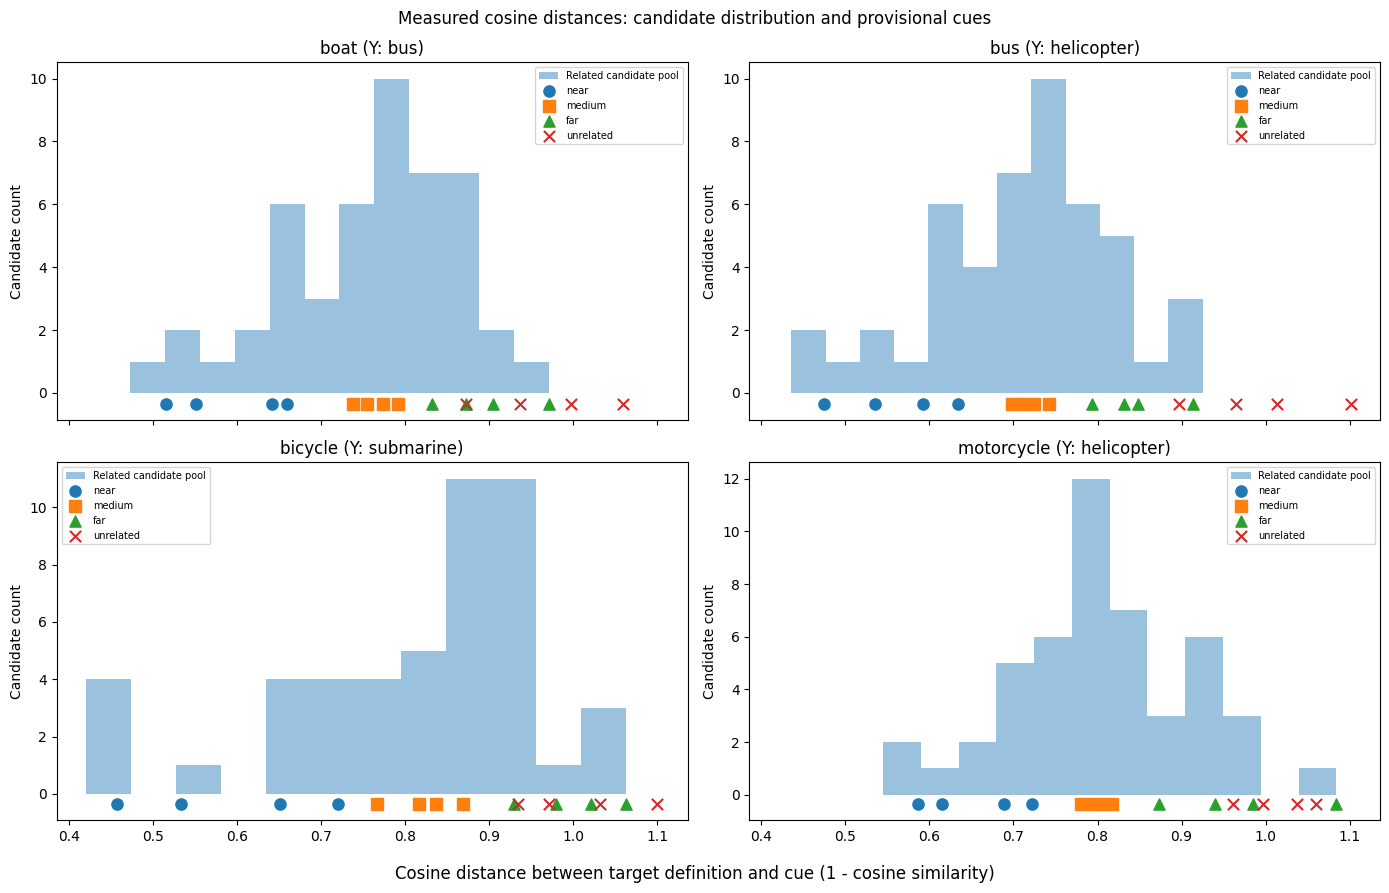

In [7]:
# 4概念の距離分布と選定位置を保存
fig,axes=plt.subplots(2,2,figsize=(14,9),sharex=True)
for ax,(x,info) in zip(axes.ravel(),TARGETS.items()):
    all_related=candidates[(candidates.target_x==x)&(~candidates.is_unrelated_control)]
    ax.hist(all_related.distance_x,bins=12,alpha=.45,label='Related candidate pool')
    for label,marker in [('near','o'),('medium','s'),('far','^'),('unrelated','x')]:
        data=selected[(selected.target_x==x)&(selected.distance_band==label)]
        ax.scatter(data.distance_x,np.full(len(data),-0.35),marker=marker,s=65,label=label)
    ax.set_title(f'{x} (Y: {info["y"]})')
    ax.set_ylabel('Candidate count')
    ax.legend(fontsize=7)
fig.suptitle('Measured cosine distances: candidate distribution and provisional cues')
fig.supxlabel('Cosine distance between target definition and cue (1 - cosine similarity)')
fig.tight_layout()
fig.savefig(OUT/'cue_distance_distributions.png',dpi=160,bbox_inches='tight')
plt.show()

## 6. 内容監査と「暫定」→「最終」の昇格

必須チェック：

1. Cueが自然な英語で、事実・文脈が成立する。
2. 近・中・遠はどれもXと**少なくとも間接的な関連**がある。遠いCueが無関係なら、その文は採用しない。
3. 同じ意味の言い換え4文が同一帯を占めない。
4. XだけでなくYがCueに直接現れず、Yを強く連想させるCueばかりになっていない。
5. 帯間の距離が十分分かれ、文長・具体性が偏りすぎない。

下の `cue_review_template.csv` をダウンロードし、`human_review_status` を `APPROVED` または `REJECTED` に変更してアップロードする。**却下が1文でもあればその場で補充・再選定を行い、版を上げる。** 今回の初期出力は必ずPROVISIONAL。

In [8]:
review=selected[['cue_id','target_x','comparator_y','distance_band','cue_text','distance_x','distance_y','word_count','seed_type','human_review_status','human_review_notes']].copy()
review.to_csv(OUT/'cue_review_template.csv',index=False)
print('Human review needed for',len(review),'selected stimuli.')
print('PENDING count:',(review.human_review_status=='PENDING').sum())
print('No FINAL stimuli are issued automatically.')

Human review needed for 64 selected stimuli.
PENDING count: 64
No FINAL stimuli are issued automatically.


## 7. メタデータ・分析要約・GitHub保存

保存は**内容が同じならスキップ**、すでに同名で違う内容があれば上書きせずエラーとする。新しい候補・変更後の選定には別 `RUN_ID` を使う。GitHub保存失敗でもCSVとZIPはローカルに残る。

In [9]:
try:
    from huggingface_hub import model_info
    embedder_revision=model_info(MODEL_ID).sha
except Exception as e:
    embedder_revision='UNAVAILABLE: '+type(e).__name__
config={
 'run_id':RUN_ID,'status':'PROVISIONAL_REQUIRES_HUMAN_REVIEW',
 'embedder':MODEL_ID,'embedder_revision':embedder_revision,
 'seed':SEED,'targets':TARGETS,'comparator_definitions':Y_DEFINITIONS,
 'selection':{'candidate_per_target':60,'related_per_target':48,'negative_per_target':12,
              'near_rank_max':.30,'medium_rank_range':[.35,.65],'far_rank_min':.70,
              'selected_per_band':4,'target_word_distance_auxiliary':True,
              'human_review_required':True,'qwen_outputs_used_for_selection':False},
 'packages':{'python':sys.version.split()[0],'torch':torch.__version__,
             'sentence_transformers':sentence_transformers.__version__,
             'pandas':pd.__version__,'numpy':np.__version__},
 'caveats':['Distance quantiles depend on the authored candidate pool and are not absolute semantic proximity.',
           'The 4 target concepts are all vehicles; conclusions cannot be generalized to other categories.',
           'Far cues require positive human relevance review; negative controls are distinct.',
           'Cue authorship is not independent of the study hypothesis; blind human auditing is recommended.',
           'Semantic distance is associated with sentence semantics, specificity, and length; not isolated causally.']
}
(OUT/'config.json').write_text(json.dumps(config,indent=2,ensure_ascii=False),encoding='utf-8')

def summarize_csv(df,cols):
    return df[cols].to_markdown(index=False,floatfmt='.3f')
summary=f"""# Cue distance selection / pilot stimuli

- **Status:** PROVISIONAL, awaiting human review. Not a final experimental stimulus set.
- Model: `{MODEL_ID}`, revision `{embedder_revision}`.
- Candidate cues: **{len(candidates)}** (60 per X; 48 related and 12 unrelated controls).
- Selected provisional cues: **{len(selected)}** (4 near + 4 medium + 4 far + 4 unrelated per X).
- No Qwen output, instruction-condition outcomes, or Probe scores were consulted.
- Definitions and Y concepts were frozen before distance measurement.

## Distance separation by target (lower = semantically closer by this embedding)

{summarize_csv(check,['target_x','mean_near','mean_medium','mean_far','near_to_medium_gap','medium_to_far_gap','low_gap_warning'])}

## Related candidate distance distribution

{candidates[~candidates.is_unrelated_control].groupby('target_x').distance_x.agg(['min','median','max']).round(3).to_markdown()}

## Required human review

Check factuality, naturalness, semantic diversity, relevance of far cues, and Y association in `cue_review_template.csv`.
**Never replace rejected cues after viewing the main experiment outcomes.**

## Files

- `cue_candidates.csv`: full candidate pool, measured X/Y distances and quality flags.
- `cue_selected_PROVISIONAL.csv`: selected 64 texts and distances.
- `cue_review_template.csv`: review sheet. The selection is not FINAL.
- `distance_separation_audit.csv`: separation flags.
- `cue_distance_distributions.png`: distance histograms and selected texts.
- `config.json`: reproducibility configuration and embedding revision.
- `manifest.json`: hashes and run completion status.
"""
(OUT/'analysis_summary.md').write_text(summary,encoding='utf-8')
# stable fingerprint of selection (excluding run-dependent timestamps)
provisional_hash=hashlib.sha256((OUT/'cue_selected_PROVISIONAL.csv').read_bytes()).hexdigest()
manifest={'status':'COMPLETED_PROVISIONAL_REQUIRES_REVIEW','run_id':RUN_ID,
          'candidate_count':len(candidates),'provisional_selection_count':len(selected),
          'approval_status':'PENDING','selection_sha256':provisional_hash,
          'files':{q.name:hashlib.sha256(q.read_bytes()).hexdigest() for q in OUT.iterdir() if q.is_file()}}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print(summary[:1900])
print('Outputs:',[x.name for x in OUT.iterdir() if x.is_file()])

# Cue distance selection / pilot stimuli

- **Status:** PROVISIONAL, awaiting human review. Not a final experimental stimulus set.
- Model: `sentence-transformers/all-mpnet-base-v2`, revision `e8c3b32edf5434bc2275fc9bab85f82640a19130`.
- Candidate cues: **240** (60 per X; 48 related and 12 unrelated controls).
- Selected provisional cues: **64** (4 near + 4 medium + 4 far + 4 unrelated per X).
- No Qwen output, instruction-condition outcomes, or Probe scores were consulted.
- Definitions and Y concepts were frozen before distance measurement.

## Distance separation by target (lower = semantically closer by this embedding)

| target_x   |   mean_near |   mean_medium |   mean_far |   near_to_medium_gap |   medium_to_far_gap | low_gap_warning   |
|:-----------|------------:|--------------:|-----------:|---------------------:|--------------------:|:------------------|
| boat       |       0.592 |         0.764 |      0.895 |                0.078 |               0.040 | False             |

In [10]:
# Save all outputs in a single ZIP first
files=sorted([q for q in OUT.iterdir() if q.is_file() and q.suffix != '.zip'])
archive=OUT/'cue_distance_selection_results.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for q in files:z.write(q,arcname=q.name)
print('ZIP:',archive,'bytes:',archive.stat().st_size)

# GitHub: upload fixed set of text outputs, plot, and ZIP; never overwrite immutable run
import base64, urllib.request, urllib.error
try:
    from google.colab import userdata
    GITHUB_TOKEN=userdata.get('GITHUB_RESULTS_TOKEN')
except Exception:
    GITHUB_TOKEN=os.environ.get('GITHUB_RESULTS_TOKEN')

def gh_upload(relative_path,content):
    api=f'https://api.github.com/repos/{REPO}/contents/{relative_path}'
    hdr={'Authorization':f'Bearer {GITHUB_TOKEN}', 'Accept':'application/vnd.github+json',
         'X-GitHub-Api-Version':'2022-11-28','Content-Type':'application/json'}
    req=urllib.request.Request(api,headers=hdr)
    try:
        with urllib.request.urlopen(req,timeout=30) as resp:
            old=json.loads(resp.read().decode())
        if old.get('size')==len(content):
            old_sha=old.get('sha')
            git_sha=hashlib.sha1(b'blob '+str(len(content)).encode()+b'\0'+content).hexdigest()
            if old_sha==git_sha:
                print('Unchanged:',relative_path);return
        raise RuntimeError('Refusing to overwrite a different saved artifact: '+relative_path)
    except urllib.error.HTTPError as e:
        if e.code!=404:raise
    payload=json.dumps({'message':'Add frozen provisional cue distance selection '+RUN_ID,
                        'content':base64.b64encode(content).decode(),'branch':'main'}).encode()
    post=urllib.request.Request(api,data=payload,headers=hdr,method='PUT')
    with urllib.request.urlopen(post,timeout=60) as resp:
        v=json.loads(resp.read().decode())
    print('Saved:',relative_path,v.get('commit',{}).get('sha','')[:8])

if GITHUB_SAVE and GITHUB_TOKEN:
    for q in files+[archive]:
        gh_upload(f'{REMOTE_ROOT}/{q.name}',q.read_bytes())
    print('GitHub results: https://github.com/'+REPO+'/tree/main/'+REMOTE_ROOT)
else:
    print('GitHub saving skipped: enable GITHUB_RESULTS_TOKEN in Colab Secrets if desired.')

ZIP: /content/20261112_cue_distance_pilot_v1/cue_distance_selection_results.zip bytes: 123965
Saved: 1112_cue_semantic_distance/results/20261112_cue_distance_pilot_v1/analysis_summary.md 56a12ece
Saved: 1112_cue_semantic_distance/results/20261112_cue_distance_pilot_v1/config.json 51b7d6f9
Saved: 1112_cue_semantic_distance/results/20261112_cue_distance_pilot_v1/cue_candidates.csv afc61eaf
Saved: 1112_cue_semantic_distance/results/20261112_cue_distance_pilot_v1/cue_distance_distributions.png dd81f995
Saved: 1112_cue_semantic_distance/results/20261112_cue_distance_pilot_v1/cue_review_template.csv 9af05350
Saved: 1112_cue_semantic_distance/results/20261112_cue_distance_pilot_v1/cue_selected_PROVISIONAL.csv 06a8ef5f
Saved: 1112_cue_semantic_distance/results/20261112_cue_distance_pilot_v1/distance_separation_audit.csv 325d92df
Saved: 1112_cue_semantic_distance/results/20261112_cue_distance_pilot_v1/manifest.json c54f3211
Saved: 1112_cue_semantic_distance/results/20261112_cue_distance_pilot_v

## 8. 次の作業（重要）

1. `analysis_summary.md` で概念別の距離帯の分離を確認する。
2. `cue_review_template.csv` を人手で確認し、**遠いCueでもXとの弱い関連性を保っているか**を重点的にチェックする。
3. NGがある場合は、候補から置き換えた**新しいRun ID**で再計測する。距離を見た後の人手修正は全て履歴に残す。
4. 64Cueの最終リストを凍結してから、4指示条件×5生成による抑制パイロットへ進む。

**このノートブック自体ではQwenの抑制実験・Probeスコア・Logit Lensは実行しない。**